# 02 - Exploratory data analysis
Blueprint P1.8: class balance per split, contract lengths, duplicate statistics and compiler versions (domain shift to SmartBugs).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
T = ROOT / 'reports' / 'tables'
F = ROOT / 'reports' / 'figures'

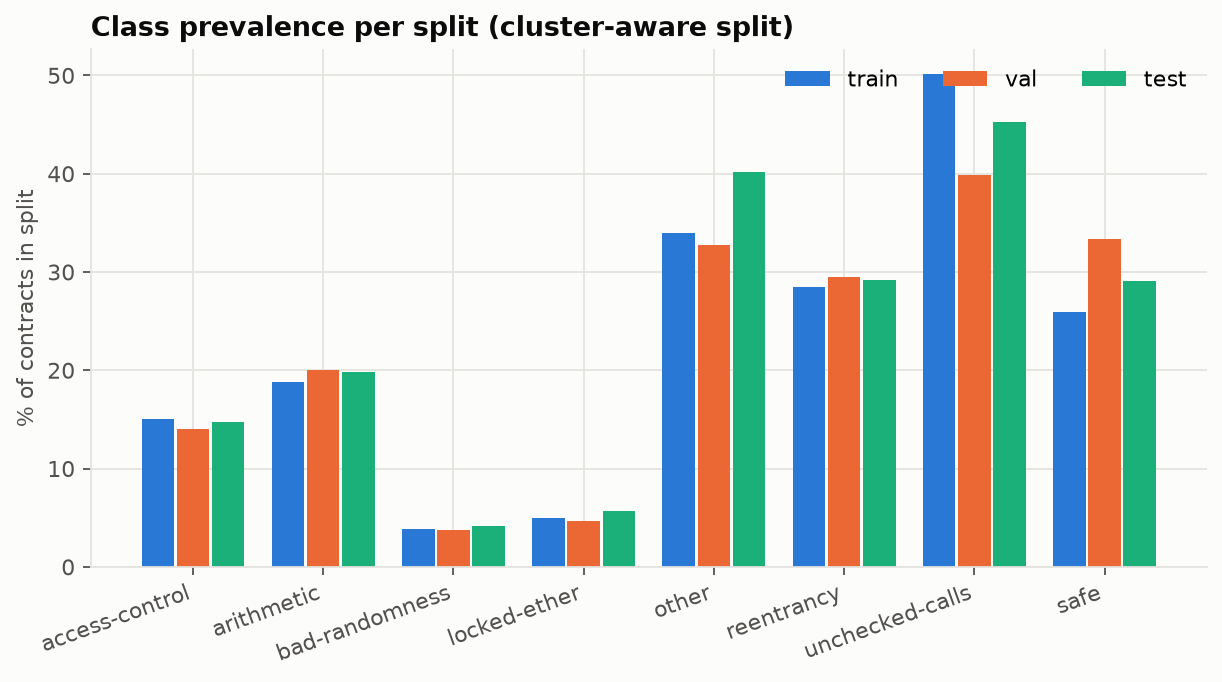

split_type      cluster                   random                 
split              test    train     val    test    train     val
class                                                            
access-control   1437.0   6850.0  1367.0  1487.0   6760.0  1407.0
arithmetic       1938.0   8564.0  1951.0  1847.0   8713.0  1893.0
bad-randomness    402.0   1732.0   369.0   357.0   1748.0   398.0
locked-ether      553.0   2276.0   458.0   508.0   2279.0   500.0
other            3916.0  15460.0  3199.0  3309.0  15879.0  3387.0
reentrancy       2853.0  12980.0  2877.0  2874.0  13042.0  2794.0
safe             2834.0  11811.0  3255.0  2706.0  12511.0  2683.0
unchecked-calls  4417.0  22832.0  3895.0  4690.0  21799.0  4655.0

In [2]:
display(Image(F / 'label_distribution.png'))
pd.read_csv(T / 'label_distribution.csv').pivot_table(index='class', columns=['split_type','split'], values='positives')

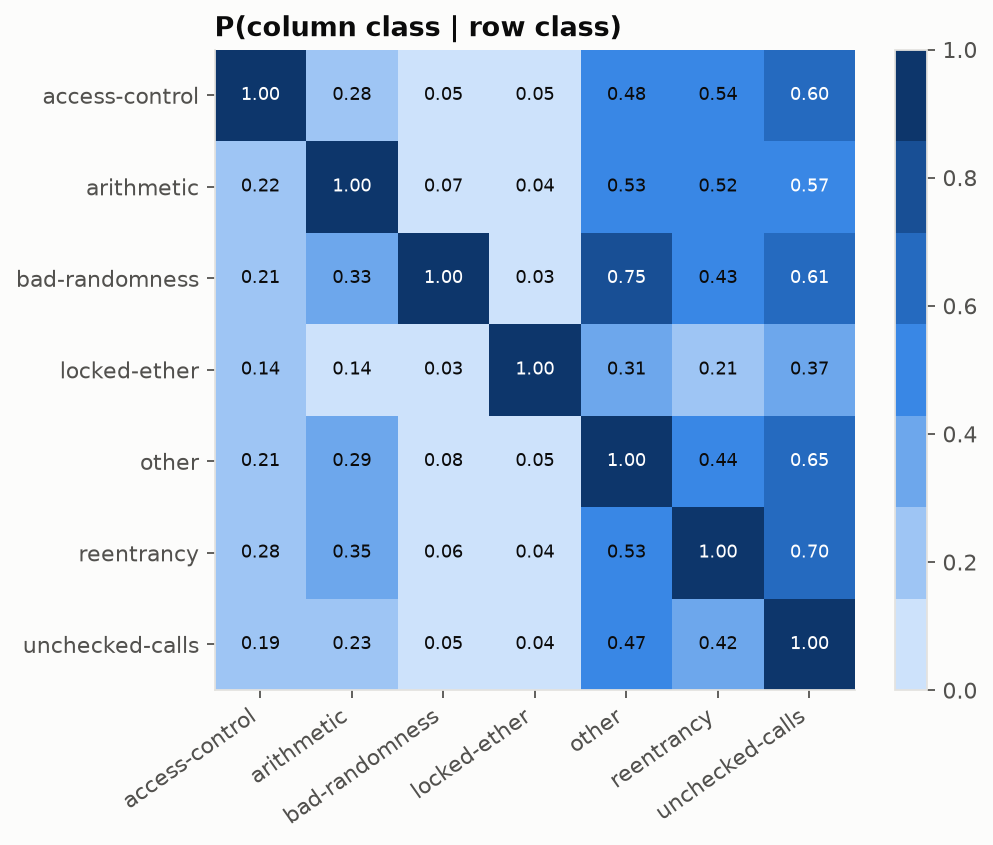

In [3]:
display(Image(F / 'label_cooccurrence.png'))

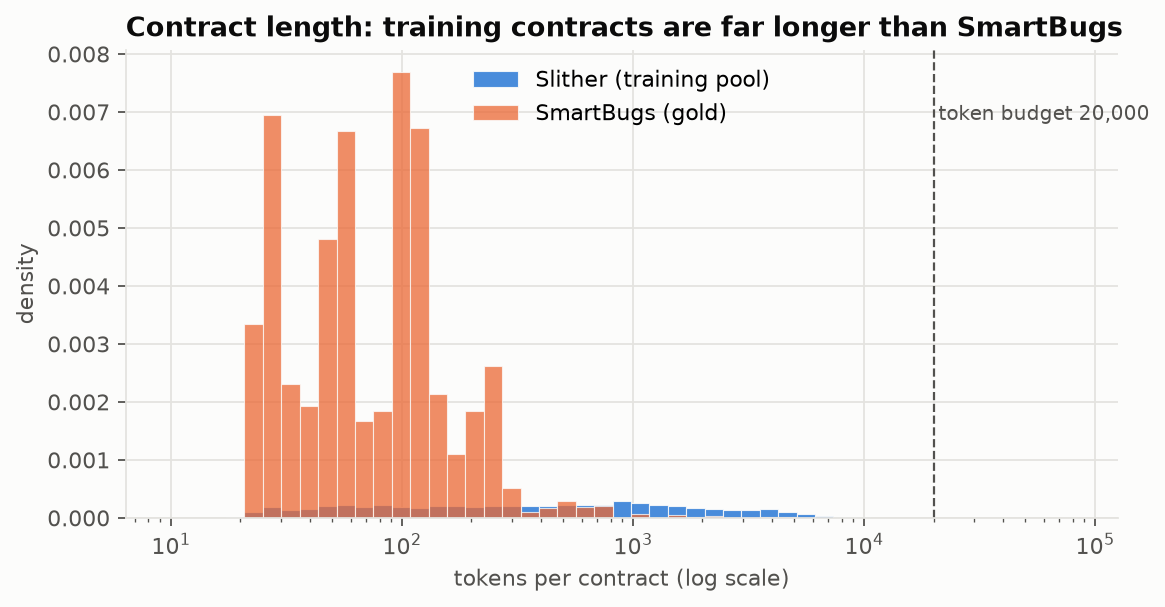

,dataset,quantile,tokens,lines
0,slither_dedup,0.50,2467.00,724.000000
1,slither_dedup,0.90,6011.30,1966.000000
2,slither_dedup,0.95,8052.30,2488.000000
3,slither_dedup,0.99,17941.40,4356.430000
4,slither_dedup,1.00,80058.00,26303.000000
5,smartbugs,0.50,127.00,42.000000
6,smartbugs,0.90,664.20,172.600000
7,smartbugs,0.95,1459.40,308.800000
8,smartbugs,0.99,4483.46,844.500000
9,smartbugs,1.00,7069.00,2470.000000


In [4]:
display(Image(F / 'length_histogram.png'))
pd.read_csv(T / 'length_stats.csv')

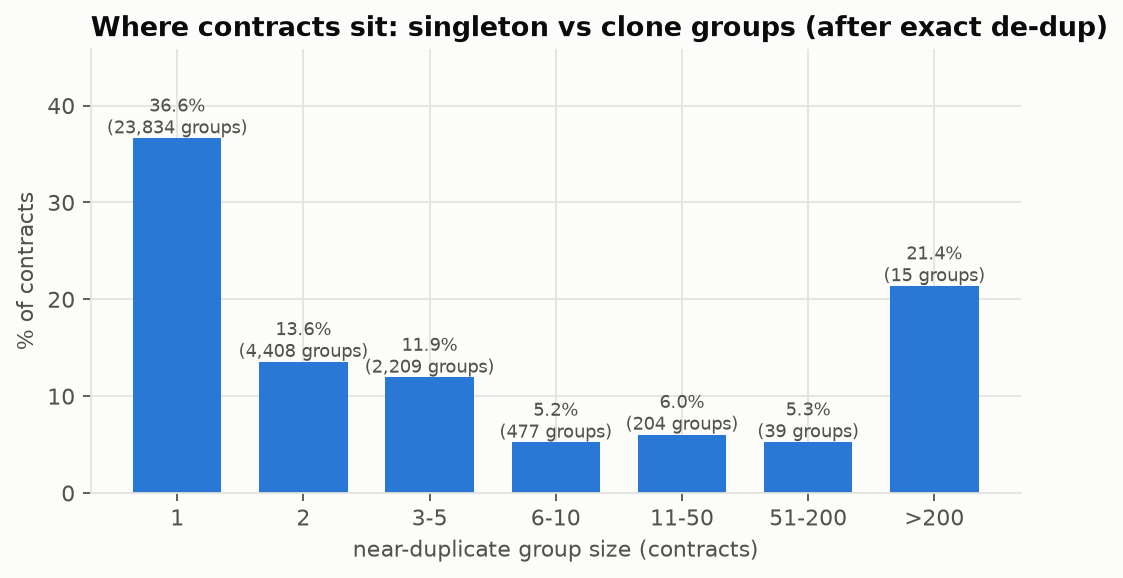

{'documents': 120510,
 'unique_exact': 65058,
 'exact_duplicates': 55452,
 'exact_duplicate_pct': 46.01443863579786,
 'near_duplicate_pairs': 1192678,
 'groups': 31186,
 'singleton_groups': 21564,
 'largest_group': 7170,
 'docs_in_multi_member_groups_pct': 82.10604929051532,
 'exact_groups_with_label_conflicts': 56,
 'exact_groups_with_duplicates': 9947,
 'random_split_leakage_rate': 0.5852034019879085,
 'group_split_leakage_rate': 0.0,
 'groups_after_exact_dedup': 31186,
 'largest_group_after_exact_dedup': 5319,
 'giant_groups_forced_to_train': 6,
 'contracts_in_giant_groups': 10085,
 'largest_group_in_val_or_test': 593}

In [5]:
display(Image(F / 'duplicate_groups.png'))
json.load(open(ROOT / 'data/processed/build_summary.json'))['dedup']

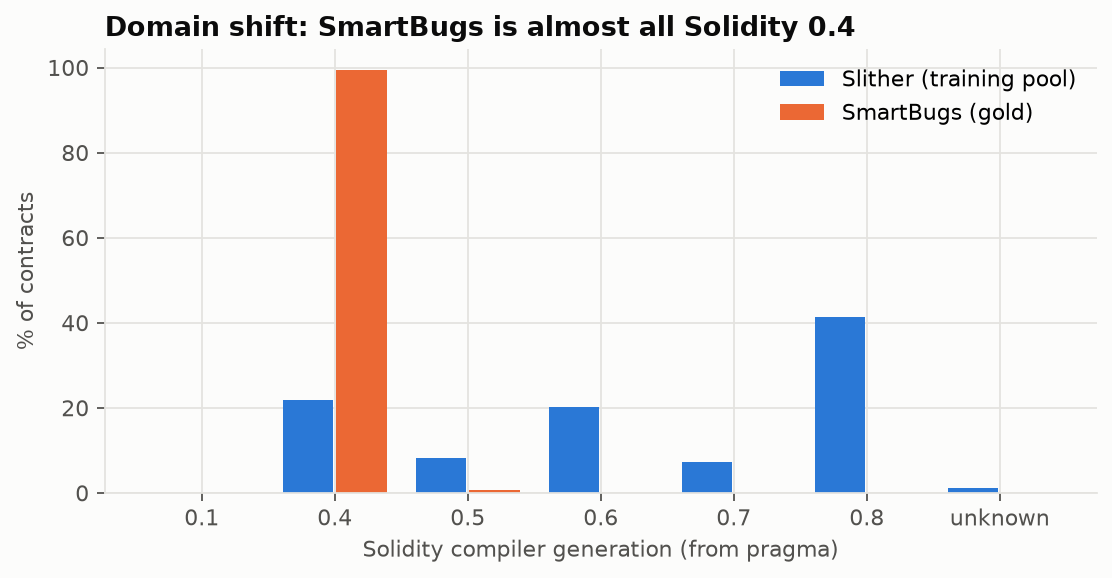

,solidity_minor,slither_dedup,smartbugs
0,0.1,0.000123,0.000000
1,0.4,0.217929,0.993007
2,0.5,0.082742,0.006993
3,0.6,0.201928,0.000000
4,0.7,0.073165,0.000000
5,0.8,0.413277,0.000000
6,unknown,0.010837,0.000000


In [6]:
display(Image(F / 'solidity_versions.png'))
pd.read_csv(T / 'solidity_versions.csv')

In [7]:
pd.read_csv(T / 'smartbugs_counts.csv')

,category,contracts,annotated_vulnerabilities,annotated_lines
0,access_control,18,21,24
1,arithmetic,15,23,23
2,bad_randomness,8,31,34
3,denial_of_service,6,7,14
4,front_running,4,7,7
5,other,3,3,5
6,reentrancy,31,32,32
7,short_addresses,1,1,1
8,time_manipulation,5,7,7
9,unchecked_low_level_calls,52,75,75
